# Encosta Segura · modelo de risco de deslizamento

**Global Solution FIAP 2026 · CitizenTech · Inteligência Artificial & Machine Learning**

| Nome | RM |
|---|---|
| Maria Eduarda Ferrés | 560418 |
| Gabriela Queiroga Cocuzza da Silva | 560035 |
| Davi Corrêa Paião | 560438 |

O Encosta Segura avisa moradores de encostas antes de um deslizamento. Uma estação com ESP32 mede o solo, a chuva e o movimento do terreno. Este notebook treina o **componente inteligente** da solução: um modelo que transforma essas leituras numa **probabilidade de deslizamento** e num nível de risco (BAIXO, ATENÇÃO ou ALTO).

**Roteiro**
1. Problema e dados
2. Preparação e análise
3. Modelo e treino
4. Avaliação com métrica
5. Integração na solução

> Para rodar: `Kernel → Restart & Run All` (ou `Ambiente de execução → Executar tudo` no Colab). Tudo usa `seed = 42`, então o resultado é sempre o mesmo.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, confusion_matrix, f1_score, make_scorer, precision_score,
                             recall_score, roc_auc_score, roc_curve, precision_recall_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
PASTA_DADOS = Path('data')
PASTA_MODELOS = Path('models')
PASTA_FIGURAS = Path('figuras')
for pasta in (PASTA_DADOS, PASTA_MODELOS, PASTA_FIGURAS):
    pasta.mkdir(exist_ok=True)

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
COR_NAO, COR_SIM = '#8a8fa3', '#ED145B'  # cinza = sem deslizamento, rosa FIAP = deslizamento

## 1. Problema e dados

### 1.1 O problema

Quem mora em encosta não sabe quando o terreno está perto de ceder. Os alertas oficiais são por cidade ou região e usam principalmente a **chuva acumulada em 72 horas**. A estação do Encosta Segura mede cada encosta de perto e precisa responder a uma pergunta simples, várias vezes por minuto:

> **Com as leituras de agora, qual é a chance de deslizamento nesta encosta?**

A resposta vira uma decisão para o morador:

| Probabilidade | Nível | O que o app manda fazer |
|---|---|---|
| menor que 30% | BAIXO | continuar acompanhando |
| de 30% a 70% | ATENÇÃO | separar documentos e ficar pronto para sair |
| 70% ou mais | ALTO | sair de casa e ir ao ponto de apoio |

São os mesmos limiares já usados no ESP32 e no app.

### 1.2 Por que os dados são simulados

Não existe base pública com **leituras de sensores da encosta** (umidade do solo e inclinação) ligadas a deslizamentos que aconteceram ou não. Por isso, a equipe **simulou** as leituras com regras baseadas em critérios reais da Defesa Civil:

- O Plano Preventivo de Defesa Civil (PPDC) de São Paulo monitora principalmente a **chuva acumulada de 72 horas** ([Revista do Departamento de Geografia, USP](https://periodicos.usp.br/rdg/article/download/165390/166516/457600)).
- Na cidade de São Paulo, o estado de **atenção** começa com **60 mm em 72 h**, e a chuva é **fraca até 5 mm/h, moderada até 30 mm/h e forte acima de 30 mm/h** ([Prefeitura de São Paulo](https://prefeitura.sp.gov.br/web/comunicacao/w/noticias/108584)).
- Na Região de Campinas, a entrada no nível de atenção é com **80 mm em 72 h** ([Atlas Público, Resolução CMIL 039/610/26](https://atlaspublico.com.br/estados/sp/noticias/casa-militar-de-sp-institui-plano-de-contingencia-contra-92507)).
- O mesmo estudo da USP cita a **umidade do solo** e as **evidências de movimento do terreno** (trincas, degraus) como sinais usados nos alertas.

### 1.3 Como a simulação funciona

Cada linha é uma leitura de uma das 8 estações fictícias do bairro Morro Verde (Vale da Serra, SP):

1. Sorteia um cenário de tempo: **seco** (50%), **chuva** (32%) ou **temporal** (18%).
2. Gera a chuva acumulada em 72 h e a intensidade da chuva conforme o cenário.
3. A umidade do solo sobe com a chuva.
4. Com o solo encharcado, o terreno pode começar a **se mover** (inclinação).
5. A chance real de deslizamento depende dessas quatro medidas **e de coisas que a estação não mede**, como o tipo de solo e o formato de cada encosta. Isso deixa o problema realista: o modelo não acerta tudo.
6. Os sensores têm **ruído de medição** e às vezes **falham** (valor vazio, fora da faixa, código de erro), como acontece no mundo real.

In [2]:
def sigmoide(z):
    return 1 / (1 + np.exp(-z))


def gerar_leituras(n=8000, seed=SEED):
    # Gera leituras simuladas das estações da encosta (veja a seção 1.3).
    rng = np.random.default_rng(seed)

    estacao = rng.integers(1, 9, n)                       # ES-01 a ES-08
    fragilidade = rng.normal(0, 0.9, 9)[estacao]          # solo/formato da encosta: a estação NÃO mede isso
    cenario = rng.choice(['seco', 'chuva', 'temporal'], n, p=[0.50, 0.32, 0.18])

    chuva_72h = np.select(
        [cenario == 'seco', cenario == 'chuva'],
        [rng.gamma(1.2, 10, n), rng.gamma(3, 15, n)],
        rng.gamma(5, 25, n))
    intensidade = np.select(
        [cenario == 'seco', cenario == 'chuva'],
        [np.where(rng.random(n) < 0.7, 0, rng.gamma(1, 2, n)), rng.gamma(2, 5, n)],
        rng.gamma(3, 12, n))
    chuva_72h = np.clip(chuva_72h, 0, 300)
    intensidade = np.clip(intensidade, 0, 100)            # o pluviômetro do ESP32 vai até 100 mm/h

    umidade = np.clip(25 + 0.35 * chuva_72h + 0.15 * intensidade + rng.normal(0, 9, n), 5, 100)

    # solo encharcado pode começar a se mover
    comecou_a_mover = rng.random(n) < sigmoide(-6.5 + 0.03 * chuva_72h + 0.05 * (umidade - 60) + fragilidade)
    inclinacao = np.abs(rng.normal(0, 0.6, n)) + np.where(comecou_a_mover, rng.gamma(2, 2.2, n), 0)

    # chance real de deslizamento (inclui o que a estação não mede + acaso)
    z = (-10.5 + 0.04 * umidade + 0.025 * chuva_72h + 0.03 * intensidade + 0.45 * inclinacao
         + 1.0 * ((umidade > 85) & (chuva_72h > 80)) + fragilidade + rng.normal(0, 1.3, n))
    deslizamento = (rng.random(n) < sigmoide(z)).astype(int)

    # o que os sensores leem (com ruído de medição)
    df = pd.DataFrame({
        'id_leitura': np.arange(1, n + 1),
        'estacao': [f'ES-{e:02d}' for e in estacao],
        'cenario': cenario,
        'umidade_solo_pct': np.clip(umidade + rng.normal(0, 6, n), 0, 100).round(1),
        'chuva_72h_mm': np.clip(chuva_72h * rng.normal(1, 0.12, n), 0, None).round(1),
        'intensidade_mm_h': np.clip(intensidade + rng.normal(0, 3, n), 0, 100).round(1),
        'inclinacao_graus': np.clip(inclinacao + rng.normal(0, 0.5, n), 0, None).round(2),
        'deslizamento': deslizamento,
    })

    # falhas de sensor, como no mundo real
    falhas = rng.choice(n, size=int(0.03 * n), replace=False)
    df.loc[falhas[:100], 'umidade_solo_pct'] = np.nan     # leitura vazia
    df.loc[falhas[100:140], 'umidade_solo_pct'] = 150.0   # fora da faixa (0 a 100%)
    df.loc[falhas[140:], 'intensidade_mm_h'] = -1.0       # código de erro do pluviômetro
    duplicadas = df.sample(25, random_state=seed)         # leituras enviadas duas vezes
    return pd.concat([df, duplicadas], ignore_index=True)


bruto = gerar_leituras()
bruto.to_csv(PASTA_DADOS / 'leituras_encosta_bruto.csv', index=False)
print(f'{len(bruto)} leituras salvas em data/leituras_encosta_bruto.csv')
bruto.head()

8025 leituras salvas em data/leituras_encosta_bruto.csv


,id_leitura,estacao,cenario,umidade_solo_pct,chuva_72h_mm,intensidade_mm_h,inclinacao_graus,deslizamento
0,1,ES-01,chuva,24.8,29.3,10.8,0.00,0
1,2,ES-07,seco,26.2,3.9,0.4,1.21,0
2,3,ES-06,seco,37.8,19.4,0.9,0.99,0
3,4,ES-04,temporal,57.8,110.9,28.6,1.20,0
4,5,ES-04,seco,29.3,31.5,0.2,0.40,0


### 1.4 Dicionário de dados

| Coluna | Unidade | O que é | Usada no modelo? |
|---|---|---|---|
| `id_leitura` | – | número da leitura | não |
| `estacao` | – | estação que mediu (ES-01 a ES-08) | não |
| `cenario` | – | tempo no momento (seco, chuva, temporal). **A estação não sabe isso**; serve só para a análise | não |
| `umidade_solo_pct` | % | umidade do solo (sensor capacitivo) | **sim** |
| `chuva_72h_mm` | mm | chuva acumulada nas últimas 72 h | **sim** |
| `intensidade_mm_h` | mm/h | intensidade da chuva agora (pluviômetro) | **sim** |
| `inclinacao_graus` | graus | quanto o terreno inclinou desde a instalação (MPU6050) | **sim** |
| `deslizamento` | 0/1 | **alvo**: 1 se houve deslizamento | alvo |

As quatro variáveis do modelo são exatamente as que o ESP32 mede, na mesma unidade.

## 2. Preparação e análise

### 2.1 Primeira olhada

In [3]:
dados = pd.read_csv(PASTA_DADOS / 'leituras_encosta_bruto.csv')
print(dados.shape)
dados.info()

(8025, 8)
<class 'pandas.DataFrame'>
RangeIndex: 8025 entries, 0 to 8024
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id_leitura        8025 non-null   int64  
 1   estacao           8025 non-null   str    
 2   cenario           8025 non-null   str    
 3   umidade_solo_pct  7924 non-null   float64
 4   chuva_72h_mm      8025 non-null   float64
 5   intensidade_mm_h  8025 non-null   float64
 6   inclinacao_graus  8025 non-null   float64
 7   deslizamento      8025 non-null   int64  
dtypes: float64(4), int64(2), str(2)
memory usage: 501.7 KB


In [4]:
dados.describe().round(2)

,id_leitura,umidade_solo_pct,chuva_72h_mm,intensidade_mm_h,inclinacao_graus,deslizamento
count,8025.00,7924.00,8025.00,8025.00,8025.00,8025.00
mean,3999.27,41.70,42.35,10.01,0.74,0.05
std,2308.32,21.81,49.45,15.25,1.22,0.21
min,1.00,0.00,0.00,-1.00,0.00,0.00
25%,2002.00,27.08,8.80,0.10,0.07,0.00
50%,3998.00,37.25,23.20,3.90,0.48,0.00
75%,5997.00,51.10,57.20,12.60,0.94,0.00
max,8000.00,150.00,337.20,100.00,15.36,1.00


O `describe` já mostra problemas: umidade com máximo **150%** (impossível), intensidade com mínimo **-1** (código de erro) e valores vazios na umidade. Também há leituras repetidas.

### 2.2 Limpeza

Decisão: **remover** as leituras com falha de sensor, em vez de inventar um valor no lugar. São só cerca de 3% das linhas, e uma leitura com defeito não deve ensinar nada ao modelo.

In [5]:
antes = len(dados)
dados = dados.drop_duplicates()
print(f'Duplicadas removidas: {antes - len(dados)}')

falha_umidade = dados['umidade_solo_pct'].isna() | ~dados['umidade_solo_pct'].between(0, 100)
falha_chuva = ~dados['intensidade_mm_h'].between(0, 100)
print(f'Umidade com falha: {falha_umidade.sum()} | Intensidade com falha: {falha_chuva.sum()}')

dados = dados[~(falha_umidade | falha_chuva)].reset_index(drop=True)
dados.to_csv(PASTA_DADOS / 'leituras_encosta_limpo.csv', index=False)
print(f'Leituras válidas: {len(dados)} (salvas em data/leituras_encosta_limpo.csv)')
print('Valores vazios restantes:', int(dados.isna().sum().sum()))

Duplicadas removidas: 25
Umidade com falha: 140 | Intensidade com falha: 100
Leituras válidas: 7760 (salvas em data/leituras_encosta_limpo.csv)
Valores vazios restantes: 0


### 2.3 Quantos deslizamentos?

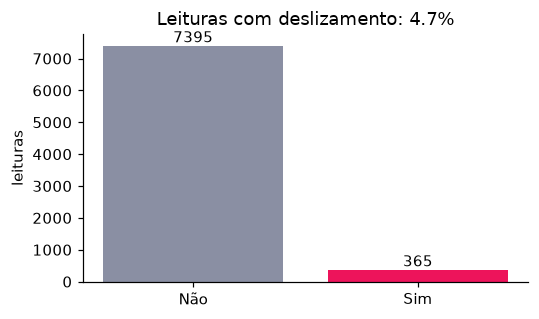

,leituras,taxa_deslizamento
cenario,,
chuva,2546,0.009
seco,3870,0.001
temporal,1344,0.252


In [6]:
contagem = dados['deslizamento'].value_counts().sort_index()
taxa = dados['deslizamento'].mean()

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(['Não', 'Sim'], contagem.values, color=[COR_NAO, COR_SIM])
for i, v in enumerate(contagem.values):
    ax.text(i, v, f'{v}', ha='center', va='bottom')
ax.set_title(f'Leituras com deslizamento: {taxa:.1%}')
ax.set_ylabel('leituras')
plt.tight_layout(); plt.show()

dados.groupby('cenario')['deslizamento'].agg(['count', 'mean']).rename(
    columns={'count': 'leituras', 'mean': 'taxa_deslizamento'}).round(3)

As classes são **desbalanceadas**: só cerca de 5% das leituras terminam em deslizamento, e quase todas em temporal. Por isso **acurácia não serve** como métrica: um modelo que sempre diz "não vai deslizar" acertaria uns 95% e não salvaria ninguém. Na seção 3 vamos provar isso com um modelo de referência.

### 2.4 Como cada medida se comporta

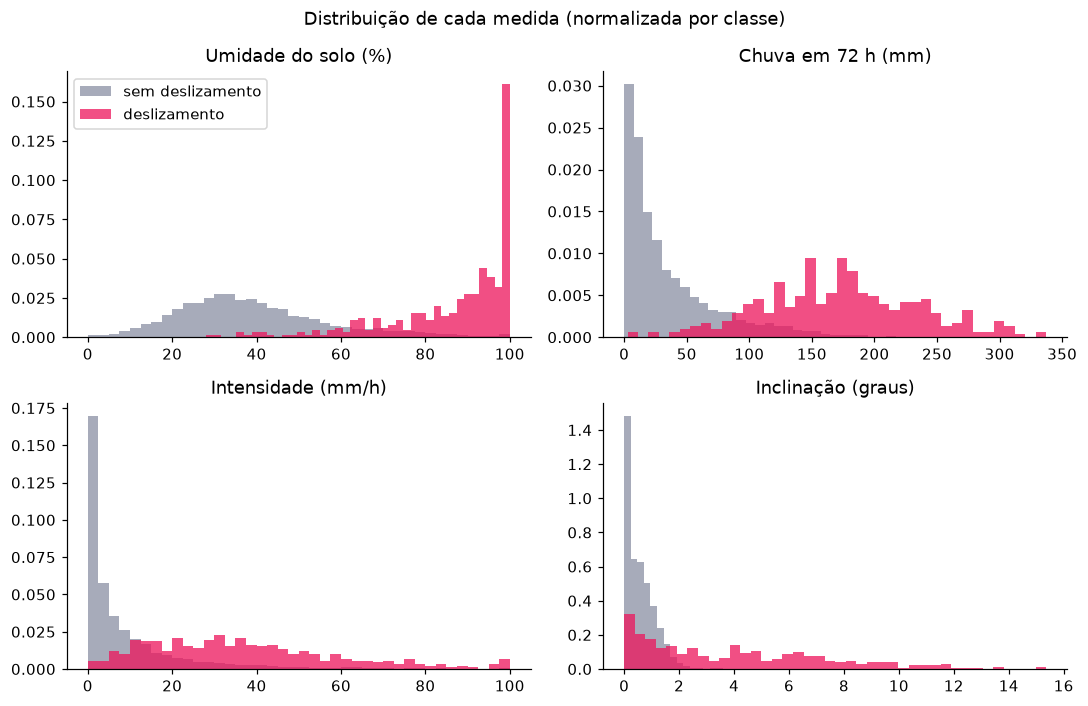

In [7]:
VARIAVEIS = ['umidade_solo_pct', 'chuva_72h_mm', 'intensidade_mm_h', 'inclinacao_graus']
NOMES = {'umidade_solo_pct': 'Umidade do solo (%)', 'chuva_72h_mm': 'Chuva em 72 h (mm)',
         'intensidade_mm_h': 'Intensidade (mm/h)', 'inclinacao_graus': 'Inclinação (graus)'}

fig, eixos = plt.subplots(2, 2, figsize=(10, 6.5))
for ax, var in zip(eixos.ravel(), VARIAVEIS):
    for classe, cor, rotulo in [(0, COR_NAO, 'sem deslizamento'), (1, COR_SIM, 'deslizamento')]:
        ax.hist(dados.loc[dados['deslizamento'] == classe, var], bins=40, color=cor,
                alpha=0.75, density=True, label=rotulo)
    ax.set_title(NOMES[var])
eixos[0, 0].legend()
fig.suptitle('Distribuição de cada medida (normalizada por classe)')
plt.tight_layout(); plt.show()

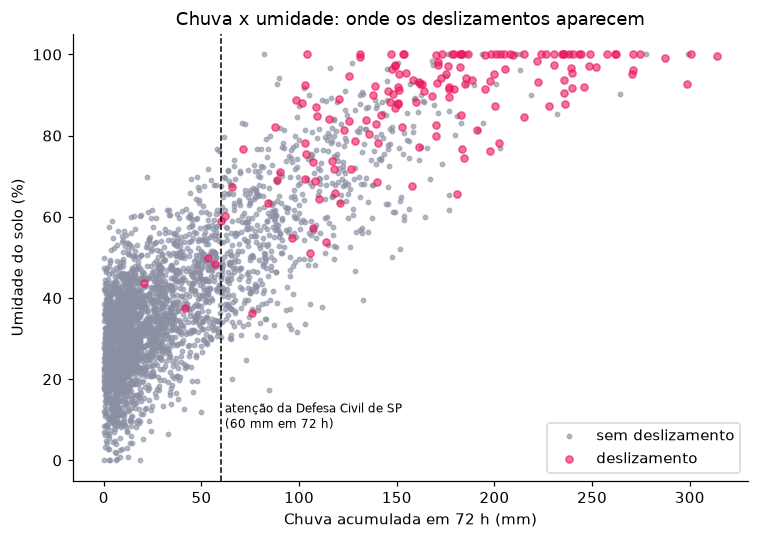

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
amostra = dados.sample(3000, random_state=SEED)
for classe, cor, rotulo, tam in [(0, COR_NAO, 'sem deslizamento', 8), (1, COR_SIM, 'deslizamento', 22)]:
    parte = amostra[amostra['deslizamento'] == classe]
    ax.scatter(parte['chuva_72h_mm'], parte['umidade_solo_pct'], s=tam, c=cor, alpha=0.6, label=rotulo)
ax.axvline(60, ls='--', c='k', lw=1)
ax.text(62, 8, 'atenção da Defesa Civil de SP\n(60 mm em 72 h)', fontsize=8)
ax.set_xlabel('Chuva acumulada em 72 h (mm)'); ax.set_ylabel('Umidade do solo (%)')
ax.set_title('Chuva x umidade: onde os deslizamentos aparecem')
ax.legend(); plt.tight_layout()
plt.savefig(PASTA_FIGURAS / 'chuva_umidade.png'); plt.show()

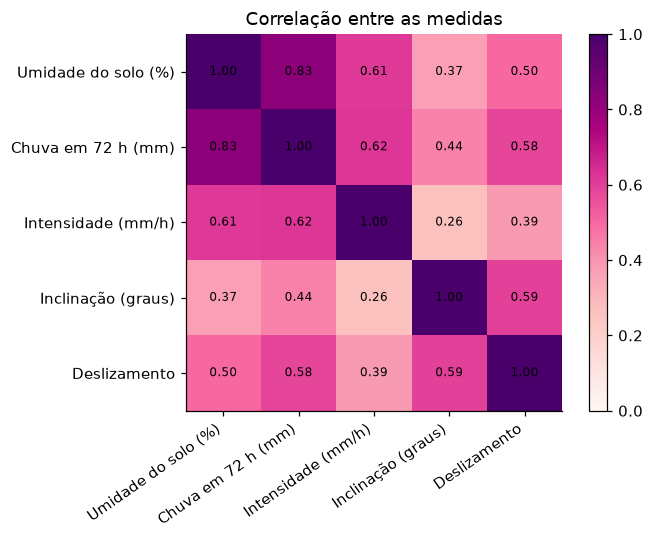

In [9]:
correlacao = dados[VARIAVEIS + ['deslizamento']].corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(correlacao, cmap='RdPu', vmin=0, vmax=1)
rotulos = [NOMES.get(c, 'Deslizamento') for c in correlacao.columns]
ax.set_xticks(range(len(rotulos)), rotulos, rotation=35, ha='right')
ax.set_yticks(range(len(rotulos)), rotulos)
for i in range(len(rotulos)):
    for j in range(len(rotulos)):
        ax.text(j, i, f'{correlacao.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im); ax.set_title('Correlação entre as medidas')
plt.tight_layout(); plt.show()

**O que a análise mostra**

- Os deslizamentos se concentram quando a **chuva em 72 h passa de uns 60 a 80 mm e o solo está acima de uns 80%**, coerente com os limiares da Defesa Civil.
- A **inclinação** separa bem os casos graves: quando o terreno começa a se mover, o risco dispara.
- Umidade e chuva acumulada são bem correlacionadas (o solo molha com a chuva), mas cada uma ainda traz informação própria.
- Há sobreposição entre as classes: nenhuma medida sozinha resolve. Faz sentido usar um modelo com as quatro juntas.

## 3. Modelo e treino

### 3.1 Separação treino e teste

75% das leituras para treinar e 25% guardadas para o teste final. A separação é **estratificada** para manter a mesma proporção de deslizamentos nas duas partes.

In [10]:
X = dados[VARIAVEIS]
y = dados['deslizamento']
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)
print(f'Treino: {len(X_treino)} leituras ({y_treino.mean():.1%} deslizamento)')
print(f'Teste:  {len(X_teste)} leituras ({y_teste.mean():.1%} deslizamento)')

Treino: 5820 leituras (4.7% deslizamento)
Teste:  1940 leituras (4.7% deslizamento)


### 3.2 Três candidatos

| Modelo | Por que testar |
|---|---|
| **Referência** (`DummyClassifier`) | Sempre diz "não vai deslizar". Mostra por que acurácia engana. |
| **KNN** | Visto na disciplina: classifica pela **distância euclidiana** até as leituras mais parecidas, a mesma ideia de similaridade vetorial do nosso Painel Multimodal. |
| **Regressão logística** | Devolve uma **probabilidade** e é uma conta simples (5 números), que cabe no ESP32. |

Os dois últimos usam `StandardScaler`, porque as medidas têm escalas muito diferentes: a chuva vai até centenas de mm e a inclinação fica em poucos graus. Sem padronizar, a chuva dominaria a distância do KNN.

Os hiperparâmetros são escolhidos com **validação cruzada estratificada de 5 partes**, usando só o treino. A métrica da busca é a **AUC-ROC**, que mede o quanto o modelo separa as classes, sem depender de um limiar.

In [11]:
validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

busca_knn = GridSearchCV(
    make_pipeline(StandardScaler(), KNeighborsClassifier()),
    {'kneighborsclassifier__n_neighbors': [5, 11, 21, 31, 45, 61, 81, 101],
     'kneighborsclassifier__weights': ['uniform', 'distance']},
    scoring='roc_auc', cv=validacao)
busca_knn.fit(X_treino, y_treino)
print('KNN - melhores parâmetros:', busca_knn.best_params_, f'| AUC na validação: {busca_knn.best_score_:.3f}')

busca_logistica = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    {'logisticregression__C': [0.01, 0.1, 1, 10, 100]},
    scoring='roc_auc', cv=validacao)
busca_logistica.fit(X_treino, y_treino)
print('Logística - melhores parâmetros:', busca_logistica.best_params_, f'| AUC na validação: {busca_logistica.best_score_:.3f}')

KNN - melhores parâmetros: {'kneighborsclassifier__n_neighbors': 81, 'kneighborsclassifier__weights': 'uniform'} | AUC na validação: 0.965
Logística - melhores parâmetros: {'logisticregression__C': 0.01} | AUC na validação: 0.975


In [12]:
candidatos = {
    'Referência (sempre "não")': DummyClassifier(strategy='most_frequent'),
    'KNN': busca_knn.best_estimator_,
    'Regressão logística': busca_logistica.best_estimator_,
}
# zero_division=0: a referência nunca prevê deslizamento, então a precisão dela é 0 (sem aviso de divisão por zero)
metricas = {'acuracia': 'accuracy', 'recall': 'recall',
            'precisao': make_scorer(precision_score, zero_division=0), 'auc_roc': 'roc_auc'}

linhas = []
for nome, modelo in candidatos.items():
    resultado = cross_validate(modelo, X_treino, y_treino, cv=validacao, scoring=metricas)
    linhas.append({'modelo': nome, **{m: resultado[f'test_{m}'].mean() for m in metricas}})
comparacao = pd.DataFrame(linhas).set_index('modelo').round(3)
comparacao

,acuracia,recall,precisao,auc_roc
modelo,,,,
"Referência (sempre ""não"")",0.953,0.000,0.000,0.500
KNN,0.973,0.551,0.813,0.965
Regressão logística,0.975,0.555,0.852,0.975


**Leitura da tabela (validação cruzada, limiar padrão de 50%)**

- A **referência** tem acurácia de uns 95% e **recall zero**: nunca avisa ninguém. É a prova de que acurácia não serve aqui.
- **KNN** e **regressão logística** separam bem as classes (AUC alta), com a logística um pouco à frente.
- Com o limiar padrão de 50%, os dois ainda **deixam passar uma parte dos deslizamentos** (recall abaixo do ideal). A seção 4 resolve isso escolhendo o limiar.

### 3.3 Modelo escolhido: regressão logística

1. **Desempenho igual ou melhor** que o KNN na AUC.
2. **Cabe no ESP32**: o modelo inteiro são 5 números (um peso por medida e o intercepto). O KNN precisaria guardar **todas** as leituras de treino na memória da placa e comparar com cada uma a cada segundo.
3. **Dá para explicar ao morador e à Defesa Civil**: cada peso diz quanto aquela medida aumenta o risco.
4. **Devolve uma probabilidade**, que vira direto os níveis BAIXO, ATENÇÃO e ALTO.

In [13]:
modelo = busca_logistica.best_estimator_   # já treinado com todo o conjunto de treino pelo GridSearchCV
modelo

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['umidade_solo_pct','chuva_72h_mm','intensidade_mm_h','inclinacao_graus']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## 4. Avaliação com métrica

### 4.1 Qual métrica importa

Os dois erros possíveis têm pesos muito diferentes:

- **Falso negativo** (o modelo diz "seguro" e a encosta desliza): **pode custar vidas**.
- **Falso positivo** (o modelo avisa e nada acontece): custa um susto e uma saída desnecessária de casa.

Por isso a métrica principal é o **recall da classe deslizamento**: de todos os deslizamentos reais, quantos o modelo avisou. A **precisão** entra junto para não virar alarme falso o tempo todo, porque morador que recebe alarme falso demais para de acreditar no app. A **AUC-ROC** mostra a qualidade geral, sem depender do limiar.

### 4.2 Resultado no teste (dados que o modelo nunca viu)

In [14]:
LIMIAR_ATENCAO = 0.30
LIMIAR_ALTO = 0.70

prob_teste = modelo.predict_proba(X_teste)[:, 1]
prob_knn = busca_knn.best_estimator_.predict_proba(X_teste)[:, 1]


def avaliar(probabilidades, limiar):
    previsto = (probabilidades >= limiar).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_teste, previsto).ravel()
    return {'recall': recall_score(y_teste, previsto), 'precisao': precision_score(y_teste, previsto, zero_division=0),
            'f1': f1_score(y_teste, previsto), 'deslizamentos avisados': f'{vp} de {vp + fn}', 'alarmes falsos': fp}


resultado_teste = pd.DataFrame({
    'Padrão do sklearn (50%)': avaliar(prob_teste, 0.50),
    'Avisar a partir de ATENÇÃO (30%)': avaliar(prob_teste, LIMIAR_ATENCAO),
    'Só nível ALTO (70%)': avaliar(prob_teste, LIMIAR_ALTO),
}).T
print(f'AUC-ROC no teste: regressão logística = {roc_auc_score(y_teste, prob_teste):.3f} | KNN = {roc_auc_score(y_teste, prob_knn):.3f}')
resultado_teste

AUC-ROC no teste: regressão logística = 0.979 | KNN = 0.968


,recall,precisao,f1,deslizamentos avisados,alarmes falsos
Padrão do sklearn (50%),0.626374,0.904762,0.74026,57 de 91,6
Avisar a partir de ATENÇÃO (30%),0.758242,0.811765,0.784091,69 de 91,16
Só nível ALTO (70%),0.472527,0.955556,0.632353,43 de 91,2


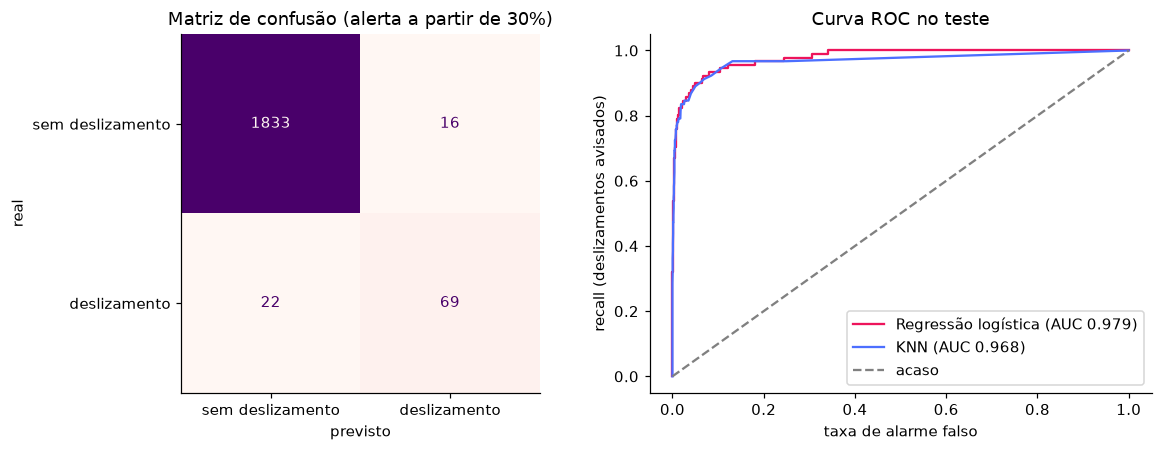

In [15]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.2))

ConfusionMatrixDisplay(confusion_matrix(y_teste, (prob_teste >= LIMIAR_ATENCAO).astype(int)),
                       display_labels=['sem deslizamento', 'deslizamento']).plot(ax=eixos[0], cmap='RdPu', colorbar=False)
eixos[0].set_title('Matriz de confusão (alerta a partir de 30%)')
eixos[0].set_xlabel('previsto'); eixos[0].set_ylabel('real')

for probs, nome, cor in [(prob_teste, 'Regressão logística', COR_SIM), (prob_knn, 'KNN', '#4C6FFF')]:
    fpr, tpr, _ = roc_curve(y_teste, probs)
    eixos[1].plot(fpr, tpr, color=cor, label=f'{nome} (AUC {roc_auc_score(y_teste, probs):.3f})')
eixos[1].plot([0, 1], [0, 1], ls='--', c='gray', label='acaso')
eixos[1].set_xlabel('taxa de alarme falso'); eixos[1].set_ylabel('recall (deslizamentos avisados)')
eixos[1].set_title('Curva ROC no teste'); eixos[1].legend(loc='lower right')
plt.tight_layout(); plt.savefig(PASTA_FIGURAS / 'avaliacao.png'); plt.show()

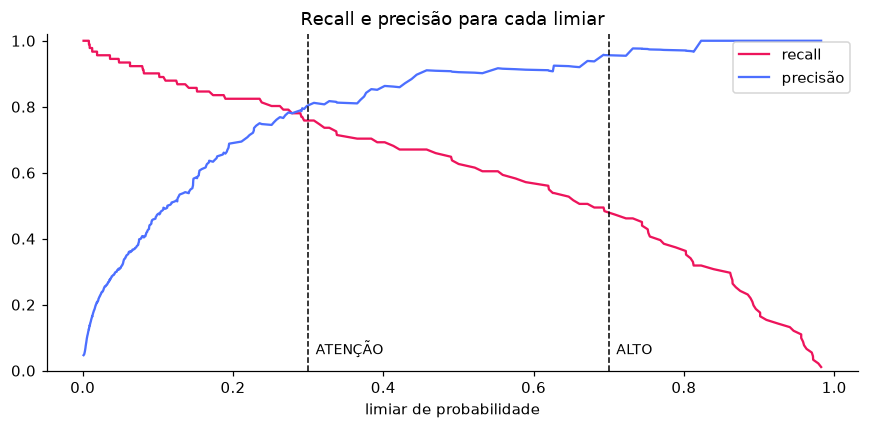

In [16]:
precisao, recall, limiares = precision_recall_curve(y_teste, prob_teste)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(limiares, recall[:-1], color=COR_SIM, label='recall')
ax.plot(limiares, precisao[:-1], color='#4C6FFF', label='precisão')
for limiar, rotulo in [(LIMIAR_ATENCAO, 'ATENÇÃO'), (LIMIAR_ALTO, 'ALTO')]:
    ax.axvline(limiar, ls='--', c='k', lw=1); ax.text(limiar + 0.01, 0.05, rotulo, fontsize=9)
ax.set_xlabel('limiar de probabilidade'); ax.set_ylim(0, 1.02)
ax.set_title('Recall e precisão para cada limiar'); ax.legend()
plt.tight_layout(); plt.show()

**Por que o alerta começa em 30% e não em 50%**

Com o limiar padrão de 50%, o modelo deixa passar muitos deslizamentos: avisa só 57 de 91 (recall de 63%). Baixando para **30%**, ele avisa 69 de 91 (recall de 76%), e a precisão cai de 90% para 81%. São 10 alarmes falsos a mais em 1.940 leituras, uma troca que vale a pena. Por isso, o app e a estação **já avisam a partir de ATENÇÃO (30%)**. O nível **ALTO (70%)** fica reservado para a ordem de sair de casa, com poucos alarmes falsos.

### 4.3 Modelo + regra de segurança do ESP32

A estação tem uma regra fixa: **se o terreno inclinar 10° ou mais, o nível vai para ALTO na hora**, seja qual for o modelo. Vamos medir quanto essa regra ajuda.

In [17]:
INCLINACAO_CRITICA = 10.0
alerta_modelo = prob_teste >= LIMIAR_ATENCAO
alerta_com_regra = alerta_modelo | (X_teste['inclinacao_graus'].to_numpy() >= INCLINACAO_CRITICA)

print(f'Recall só com o modelo:      {recall_score(y_teste, alerta_modelo):.1%}')
print(f'Recall modelo + regra 10°:  {recall_score(y_teste, alerta_com_regra):.1%}')
print(f'Precisão modelo + regra 10°: {precision_score(y_teste, alerta_com_regra):.1%}')

Recall só com o modelo:      75.8%
Recall modelo + regra 10°:  75.8%
Precisão modelo + regra 10°: 81.2%


**Resultado:** no teste, a regra **não mudou o recall**. Nos dados simulados, quando o terreno inclina 10° ou mais, o modelo já dá risco alto.

Mesmo assim, ela continua no ESP32 como **rede de segurança** para o que os dados não cobrem, como um terreno que se move sem chuva (cano vazando, obra ou corte no barranco). Um modelo aprende só com os dados que viu; uma regra física simples, fácil de conferir, cobre o resto.

### 4.4 O que o modelo aprendeu

Os pesos abaixo estão na **unidade original** de cada sensor (a conversão está na seção 5). A coluna "multiplica a chance por" mostra quanto a chance de deslizamento (em razão de chances) aumenta para cada passo daquela medida.

In [18]:
padronizador = modelo.named_steps['standardscaler']
logistica = modelo.named_steps['logisticregression']

# volta os pesos para a unidade original de cada sensor
pesos_originais = logistica.coef_[0] / padronizador.scale_
intercepto_original = logistica.intercept_[0] - np.sum(logistica.coef_[0] * padronizador.mean_ / padronizador.scale_)

passos = {'umidade_solo_pct': 10, 'chuva_72h_mm': 10, 'intensidade_mm_h': 10, 'inclinacao_graus': 1}
interpretacao = pd.DataFrame({
    'peso (unidade original)': pesos_originais,
    'passo': [f"+{passos[v]} {'%' if 'umidade' in v else 'mm' if 'chuva' in v else 'mm/h' if 'intensidade' in v else 'grau'}" for v in VARIAVEIS],
    'multiplica a chance por': np.exp(pesos_originais * np.array([passos[v] for v in VARIAVEIS])),
}, index=[NOMES[v] for v in VARIAVEIS]).round(3)
print(f'Intercepto: {intercepto_original:.3f}')
interpretacao

Intercepto: -6.964


,peso (unidade original),passo,multiplica a chance por
Umidade do solo (%),0.030,+10 %,1.355
Chuva em 72 h (mm),0.013,+10 mm,1.142
Intensidade (mm/h),0.020,+10 mm/h,1.221
Inclinação (graus),0.409,+1 grau,1.506


**Leitura:** todas as medidas aumentam o risco, como esperado pela física do problema. A **inclinação** é a mais forte por unidade: cada grau de movimento multiplica bastante a chance, o que confirma que o terreno se mexendo é o sinal mais grave.

### 4.5 Limitações (sendo honestos)

- Com o alerta a partir de 30%, o modelo avisou **76% dos deslizamentos** do teste: ainda escapa 1 em cada 4. Com dados reais, a equipe deve avaliar com a Defesa Civil se vale baixar o limiar de ATENÇÃO, aceitando mais alarmes falsos.
- Os dados são **simulados**. Antes de usar de verdade, o modelo precisa ser retreinado com leituras reais das estações e com o histórico de deslizamentos da Defesa Civil.
- O modelo não sabe o **tipo de solo** nem o **formato** de cada encosta. Isso explica parte dos erros e é o próximo dado a coletar.
- Uma regressão logística só aprende relações "em linha reta" na escala das chances. Se os dados reais mostrarem efeitos mais complexos, vale testar modelos como árvores de decisão, desde que continuem cabendo no ESP32.

## 5. Integração na solução

A previsão aparece em **três pontos** do Encosta Segura:

1. **Estação ESP32** (Physical Computing): calcula a probabilidade a cada segundo, acende o LED do nível e mostra no LCD.
2. **API** (SOA): recebe o JSON da estação com o campo `probabilidade`.
3. **App do morador** (Mobile) e **painel da Defesa Civil** (C#): mostram a chance de risco e o nível.

Para isso, o modelo treinado aqui vira **5 números** que são colados no `sketch.ino`.

### 5.1 Conferindo a conversão

O modelo foi treinado com dados padronizados, mas o ESP32 lê os valores crus dos sensores. A conversão da seção 4.4 tem que dar **exatamente** a mesma probabilidade que o modelo do sklearn:

In [19]:
def probabilidade_esp32(leituras):
    # A mesma conta que o ESP32 faz, com os sensores na unidade original.
    z = intercepto_original + np.asarray(leituras, dtype=float) @ pesos_originais
    return sigmoide(z)


diferenca = np.max(np.abs(probabilidade_esp32(X_teste.to_numpy()) - prob_teste))
print(f'Maior diferença entre o sklearn e a conta do ESP32: {diferenca:.2e}')
assert diferenca < 1e-9, 'a conversão dos coeficientes está errada'
print('Conversão conferida: o ESP32 vai calcular a mesma probabilidade do notebook.')

Maior diferença entre o sklearn e a conta do ESP32: 4.44e-16
Conversão conferida: o ESP32 vai calcular a mesma probabilidade do notebook.


### 5.2 Código para colar no `sketch.ino`

Substitua o bloco "Modelo de risco" no topo do `sketch.ino` (projeto do Wokwi) pelo trecho gerado abaixo:

In [20]:
trecho_cpp = f'''// ---------------- Modelo de risco ----------------
// Regressão logística treinada no notebook de IA/ML (encosta_segura_ml.ipynb, seed 42)
// p = 1 / (1 + e^-(B_INTERCEPTO + B_SOLO*solo + B_ACUM*acumulada + B_INT*intensidade + B_INCL*inclinacao))
const float B_INTERCEPTO = {intercepto_original:.5f};
const float B_SOLO = {pesos_originais[0]:.5f};   // por ponto de umidade (%)
const float B_ACUM = {pesos_originais[1]:.5f};   // por mm acumulado em 72 h
const float B_INT  = {pesos_originais[2]:.5f};   // por mm/h de intensidade
const float B_INCL = {pesos_originais[3]:.5f};   // por grau de inclinação

const float LIMIAR_ATENCAO     = {LIMIAR_ATENCAO:.2f};  // p >= 30%  -> ATENÇÃO
const float LIMIAR_ALTO        = {LIMIAR_ALTO:.2f};  // p >= 70%  -> ALTO
const float INCLINACAO_CRITICA = {INCLINACAO_CRITICA:.1f};  // regra de segurança: >= 10° = ALTO sempre'''
print(trecho_cpp)

// ---------------- Modelo de risco ----------------
// Regressão logística treinada no notebook de IA/ML (encosta_segura_ml.ipynb, seed 42)
// p = 1 / (1 + e^-(B_INTERCEPTO + B_SOLO*solo + B_ACUM*acumulada + B_INT*intensidade + B_INCL*inclinacao))
const float B_INTERCEPTO = -6.96354;
const float B_SOLO = 0.03038;   // por ponto de umidade (%)
const float B_ACUM = 0.01326;   // por mm acumulado em 72 h
const float B_INT  = 0.01993;   // por mm/h de intensidade
const float B_INCL = 0.40921;   // por grau de inclinação

const float LIMIAR_ATENCAO     = 0.30;  // p >= 30%  -> ATENÇÃO
const float LIMIAR_ALTO        = 0.70;  // p >= 70%  -> ALTO
const float INCLINACAO_CRITICA = 10.0;  // regra de segurança: >= 10° = ALTO sempre


### 5.3 Salvando o modelo

In [21]:
joblib.dump(modelo, PASTA_MODELOS / 'modelo_risco.joblib')

coeficientes = {
    'modelo': 'regressao_logistica',
    'variaveis': VARIAVEIS,
    'intercepto': round(float(intercepto_original), 6),
    'pesos': {v: round(float(p), 6) for v, p in zip(VARIAVEIS, pesos_originais)},
    'limiares': {'atencao': LIMIAR_ATENCAO, 'alto': LIMIAR_ALTO, 'inclinacao_critica_graus': INCLINACAO_CRITICA},
    'metricas_teste': {
        'auc_roc': round(float(roc_auc_score(y_teste, prob_teste)), 4),
        'recall_limiar_atencao': round(float(recall_score(y_teste, prob_teste >= LIMIAR_ATENCAO)), 4),
        'precisao_limiar_atencao': round(float(precision_score(y_teste, prob_teste >= LIMIAR_ATENCAO)), 4),
    },
}
(PASTA_MODELOS / 'coeficientes_esp32.json').write_text(json.dumps(coeficientes, indent=2, ensure_ascii=False), encoding='utf-8')
print('Salvos: models/modelo_risco.joblib e models/coeficientes_esp32.json')
print(json.dumps(coeficientes, indent=2, ensure_ascii=False))

Salvos: models/modelo_risco.joblib e models/coeficientes_esp32.json
{
  "modelo": "regressao_logistica",
  "variaveis": [
    "umidade_solo_pct",
    "chuva_72h_mm",
    "intensidade_mm_h",
    "inclinacao_graus"
  ],
  "intercepto": -6.963539,
  "pesos": {
    "umidade_solo_pct": 0.030379,
    "chuva_72h_mm": 0.013262,
    "intensidade_mm_h": 0.01993,
    "inclinacao_graus": 0.409207
  },
  "limiares": {
    "atencao": 0.3,
    "alto": 0.7,
    "inclinacao_critica_graus": 10.0
  },
  "metricas_teste": {
    "auc_roc": 0.9787,
    "recall_limiar_atencao": 0.7582,
    "precisao_limiar_atencao": 0.8118
  }
}


### 5.4 A previsão em uso

A função abaixo faz o que a solução inteira faz com uma leitura: calcula a probabilidade, aplica a regra de segurança e devolve o nível. Ela **carrega o modelo salvo**, como faria a API.

In [22]:
modelo_salvo = joblib.load(PASTA_MODELOS / 'modelo_risco.joblib')
O_QUE_FAZER = {
    'BAIXO': 'Tudo tranquilo. Continue acompanhando pelo app.',
    'ATENÇÃO': 'Separe documentos, remédios e carregador. Fique pronto para sair.',
    'ALTO': 'Saia de casa agora e vá para o ponto de apoio.',
}


def prever_risco(umidade_solo_pct, chuva_72h_mm, intensidade_mm_h, inclinacao_graus):
    leitura = pd.DataFrame([[umidade_solo_pct, chuva_72h_mm, intensidade_mm_h, inclinacao_graus]], columns=VARIAVEIS)
    probabilidade = float(modelo_salvo.predict_proba(leitura)[0, 1])
    if inclinacao_graus >= INCLINACAO_CRITICA or probabilidade >= LIMIAR_ALTO:
        nivel = 'ALTO'
    elif probabilidade >= LIMIAR_ATENCAO:
        nivel = 'ATENÇÃO'
    else:
        nivel = 'BAIXO'
    return {'probabilidade': round(probabilidade, 3), 'nivel': nivel, 'o_que_fazer': O_QUE_FAZER[nivel]}


cenarios = {
    'Dia seco': (35, 5, 0, 0.3),
    'Chuva moderada há 2 dias': (68, 55, 12, 0.6),
    'Temporal com solo encharcado': (93, 140, 55, 1.5),
    'Temporal e o terreno começou a se mover': (95, 160, 60, 6.0),
    'Sem chuva, mas terreno inclinou 11°': (40, 10, 0, 11.0),
}
pd.DataFrame({nome: prever_risco(*valores) for nome, valores in cenarios.items()}).T

,probabilidade,nivel,o_que_fazer
Dia seco,0.003,BAIXO,Tudo tranquilo. Continue acompanhando pelo app.
Chuva moderada há 2 dias,0.025,BAIXO,Tudo tranquilo. Continue acompanhando pelo app.
Temporal com solo encharcado,0.361,ATENÇÃO,"Separe documentos, remédios e carregador. Fiqu..."
Temporal e o terreno começou a se mover,0.845,ALTO,Saia de casa agora e vá para o ponto de apoio.
"Sem chuva, mas terreno inclinou 11°",0.247,ALTO,Saia de casa agora e vá para o ponto de apoio.


O JSON que a estação envia para a API leva o campo `probabilidade` calculado com esses mesmos coeficientes. No app do morador, ele aparece como **"Chance de risco"** nas leituras da estação, e o nível define a mensagem de "O que fazer".

## Conclusão

- **Problema:** estimar, com as leituras da encosta, a chance de deslizamento para avisar o morador a tempo.
- **Dados:** 8.000 leituras simuladas com base nos critérios do PPDC (chuva de 72 h, intensidade, umidade e movimento do terreno), com ruído e falhas de sensor tratadas na limpeza.
- **Modelo:** regressão logística, comparada com uma referência e com KNN, e escolhida por desempenho, explicabilidade e por caber no ESP32.
- **Métrica:** recall da classe deslizamento. Com o alerta a partir de 30%, o modelo avisou 76% dos deslizamentos do teste, com 81% de precisão e AUC-ROC de 0,98 (contra 0,97 do KNN).
- **Integração:** os coeficientes vão para o `sketch.ino`, e a probabilidade aparece no LCD da estação, na API, no app e no painel da Defesa Civil.